# Studying joint effects with GP descriptors

How does the structure of an attribute's gradual relationships change when other attributes must agree with it? We study **joint gradual behavior** by comparing each individual gradual item (GI) with the gradual pattern (GP) formed by their intersection.

The proposed hypothesis is that a structurally coherent composition should exhibit a well-organized progression of index relationships, and be more coherent than the individual GIs from which it is formed. Its desired descriptor profile is

$$
\kappa_g \rightarrow 1,\qquad Si_g \rightarrow 0,\qquad \sigma_g^2 \rightarrow 0.
$$

Here, **high connectivity** means one connected component, **low singularity** means more even participation of observations, and **low rank-gap variance** means more consistent index separations. We use this profile as a hypothesis about **DTW-like structural coherence**, and test each part against the actual constituents. We do not assume that intersection improves every descriptor.

By the end, you will have individual GI and joint GP descriptor tables, matched before/after differences, and plots of the exact index pairs being compared. The rainfall and vegetation datasets are analyzed independently.


## 1. Set up and load ordered observations

From the repository root, install the checkout and notebook tools in your environment if needed:

```sh
python -m pip install -e .
python -m pip install jupyterlab ipykernel
python -m jupyterlab examples/ftgp_composition.ipynb
```

Choose that environment's kernel and run all cells in order. The data lookup below supports a working directory of either the repository root or `examples/`. This walkthrough uses GRAANK with strict comparisons, rather than a temporal lag estimation algorithm. The historical notebook filename is retained.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from so4gp import GP, GI
from so4gp.algorithms import GRAANK

pd.set_option("display.max_rows", 40)
min_sup = 0.5
eq = False


In [2]:
data_candidates = [Path.cwd() / "datasets", Path.cwd() / "examples" / "datasets"]
data_dir = next(
    (path for path in data_candidates if (path / "ke_rain_data_2k.csv").is_file()),
    None,
)
if data_dir is None:
    raise FileNotFoundError("Run from the repository root or examples/ directory.")


def load_series(filename):
    frame = pd.read_csv(data_dir / filename)
    frame.columns = frame.columns.str.strip()
    dates = pd.to_datetime(frame.iloc[:, 0], format="%m-%Y", errors="raise")
    values = frame.iloc[:, 1:].apply(pd.to_numeric, errors="raise")
    if not np.isfinite(values.to_numpy()).all():
        raise ValueError("Resolve missing or non-finite values before comparing pair sets.")
    values.index = pd.DatetimeIndex(dates, name="Date")
    if values.index.has_duplicates:
        raise ValueError("Resolve duplicate dates before interpreting index distances.")
    return values.sort_index()


datasets = {
    "Rainfall": load_series("ke_rain_data_2k.csv"),
    "EVI": load_series("ke_evi_data_2k.csv"),
}
for name, frame in datasets.items():
    print(f"{name}: {len(frame)} observations, {frame.index.min():%Y-%m} to {frame.index.max():%Y-%m}")
    display(frame.head())


Rainfall: 23 observations, 2000-07 to 2022-07


,NRB (mm),KAK (mm),MAK (mm),WAJ (mm)
Date,,,,
2000-07-01,22.01000,526.8000,18.45,12.219990
2001-07-01,57.55001,539.0801,0.90,13.440000
2002-07-01,45.17000,349.2700,20.47,15.320000
2003-07-01,77.08001,660.0199,2.27,8.940001
2004-07-01,16.48000,424.6999,0.71,4.819999


EVI: 23 observations, 2000-07 to 2022-07


,NRB (EVI),KAK (EVI),MAK (EVI),WAJ (EVI)
Date,,,,
2000-07-01,0.094866,0.401556,0.160511,0.120766
2001-07-01,0.236884,0.417010,0.183184,0.152754
2002-07-01,0.243191,0.370047,0.206061,0.109228
2003-07-01,0.202896,0.423199,0.159602,0.109228
2004-07-01,0.119559,0.378931,0.178707,0.099040


The supplied files contain **23 July observations, 2000–2022**, with four attributes each: NRB, KAK, MAK and WAJ. Rainfall is measured in mm; EVI is a vegetation index. We trim whitespace from headers, parse dates and sort chronologically. We do not resample or impute data. Dates remain the DataFrame index, so only the four numerical attributes enter mining.

In the plots, $i$ and $j$ are **row indices of two observations from the same dataset**. They are not separate rainfall and EVI timelines. On these yearly observations, a gap of one row represents one year. For irregular sampling, index gaps need not represent equal elapsed times.


## 2. From a GI to a joint GP

For strict comparisons, a positive GI $A^+$ retains directed pairs for which $A_j>A_i$; a negative GI $A^-$ retains pairs for which $A_j<A_i$. A pair may point backward in chronological order: a gradual increase describes value ordering, not necessarily an increase over time.

Write the gradual warping set (GWS) of an item $g$ as $W_g$. Combining GIs means imposing all their constraints on the **same** pair:

$$
W_{\{A^+,B^-\}}=W_{A^+}\cap W_{B^-},\qquad
W_{\{g_1,\ldots,g_m\}}=\bigcap_{r=1}^{m}W_{g_r}.
$$

The code implements this intersection by **bitwise AND** of SO4GP's packed pairwise matrices. Adding constraints can only remove pairs. Density therefore cannot increase; connectivity, singularity and rank dispersion have to be measured.

### What does “DTW-like” mean here?

We examine whether the retained pairs form a coherent progression in index space. A standard DTW alignment is an ordered, monotone sequence with boundary and local-step constraints, optimized using an alignment cost ([DTW definition](https://tslearn.readthedocs.io/en/stable/user_guide/dtw.html#optimization-problem)). A GWS is a set of directed comparisons; strict comparisons even exclude self-pairs. Its descriptors summarize geometry and participation, without proving those DTW constraints or computing a DTW distance.

| Descriptor | Definition used here | Reading for the hypothesis |
|---|---|---|
| Density | $|W_g|/\binom{n}{2}$ | Context: how many comparisons survive, not a path-quality score. |
| Avg. Deviation from Diagonal | Mean of $|i-j|$ | Typical index separation; a constant but large offset can still have low variance. |
| Rank Dispersion, $\sigma_g$ | Population standard deviation of $|i-j|$ | SO4GP's reported dispersion. |
| Rank variance, $\sigma_g^2$ | Population variance of $|i-j|$ | Lower means more consistent separations; this matches the proposed hypothesis. |
| Graph Connectivity, $\kappa_g$ | Connected-component count of the undirected observation graph | The target is **1**, not a large number. SO4GP counts only observations appearing in pairs. |
| Singularity Score, $Si_g$ | $\mathrm{Var}(d)/\mathrm{mean}(d)$, with $d$ the undirected degrees over all $n$ observations | Lower means more even participation; higher means concentration around fewer observations. |

We also report **Active coverage**, the fraction of observations appearing in at least one pair, so that $\kappa_g=1$ cannot hide excluded observations. Connectivity concerns the observation graph; it does not establish a continuous path between neighboring cells in the $(i,j)$ plot.


## 3. Discover candidate GPs

Mine each dataset independently, retaining the existing support threshold of `0.5`. These mined patterns supply the candidate compositions for the matched analysis. Confidence is omitted from the structural comparisons because no consequent is selected.


In [3]:
miners = {}
mined_tables = []
for name, frame in datasets.items():
    miner = GRAANK(frame, min_sup=min_sup, eq=eq, device="cpu")
    _ = miner.discover(compute_descriptors=True, save_results=False)
    miners[name] = miner
    table = miner.mining_engine.display_patterns_as_df.copy()
    numeric_columns = table.columns.drop("Pattern")
    table[numeric_columns] = table[numeric_columns].apply(pd.to_numeric)
    table.insert(0, "Dataset", name)
    mined_tables.append(table)

mined_df = pd.concat(mined_tables, ignore_index=True)
display(mined_df.drop(columns="Confidence"))


,Dataset,Pattern,Support,Density,Avg. Deviation from Diagonal,Rank Dispersion,Graph Connectivity,Singularity Score
0,Rainfall,"NRB (mm)+, KAK (mm)+",0.688,0.688,8.011,5.381,1,0.525
1,Rainfall,"NRB (mm)+, MAK (mm)+",0.557,0.557,7.291,4.926,1,1.902
2,Rainfall,"NRB (mm)+, WAJ (mm)+",0.581,0.581,7.769,5.154,1,1.333
3,Rainfall,"KAK (mm)+, MAK (mm)+",0.506,0.506,8.281,5.404,1,1.206
4,Rainfall,"KAK (mm)+, WAJ (mm)+",0.506,0.506,7.992,5.332,1,1.518
5,Rainfall,"MAK (mm)+, WAJ (mm)+",0.585,0.585,8.095,5.515,1,1.556
6,EVI,"NRB (EVI)+, KAK (EVI)+",0.545,0.545,7.877,5.216,1,1.159
7,EVI,"NRB (EVI)+, MAK (EVI)+",0.534,0.534,8.156,5.446,1,1.357
8,EVI,"NRB (EVI)+, WAJ (EVI)-",0.526,0.526,7.774,5.322,1,1.172
9,EVI,"KAK (EVI)+, MAK (EVI)-",0.636,0.636,8.311,5.706,1,0.826


## 4. Measure constituents and compositions the same way

The following helpers are local to this walkthrough. `describe_pairs` calls `GP.compute_descriptors` on a NumPy edge array. It additionally computes the unrounded population variance from the index gaps; SO4GP rounds its reported standard deviation to three decimals.

`compose_pattern` reconstructs a GI or GP directly from `valid_bins`, using the same observation count for all comparisons. Empty intersections have zero density and coverage, but undefined geometry (`NaN`); they must not look like perfect zero-dispersion compositions.

In strict mode, the retained-pair fraction is the density and also the pair-count support of a composed GP. The stored **GI mining support** in `valid_bins` uses the larger chronological triangle of the GI bitmap; it can differ from GI density. We use pair sets and their density consistently below, and do not substitute stored GI support for geometry.


In [4]:
STRUCTURAL = [
    "Density", "Avg. Deviation from Diagonal", "Rank Dispersion",
    "Rank variance", "Graph Connectivity", "Singularity Score",
]


def describe_pairs(pairs, n):
    pairs = np.asarray(pairs, dtype=int).reshape(-1, 2)
    result = {column: np.nan for column in STRUCTURAL}
    result.update({
        "Pairs": len(pairs),
        "Active coverage": len(np.unique(pairs)) / n,
        "Density": len(pairs) / GP.pair_count(n),
    })
    if len(pairs):
        gp = GP()
        if not gp.compute_descriptors(pairs, obj_count=n):
            raise ValueError("SO4GP could not describe the pair set.")
        result.update({
            "Density": gp.density,
            "Avg. Deviation from Diagonal": gp.avg_deviation_from_diagonal,
            "Rank Dispersion": gp.rank_dispersion,
            "Rank variance": float(np.var(np.abs(pairs[:, 0] - pairs[:, 1]))),
            "Graph Connectivity": gp.graph_connectivity,
            "Singularity Score": gp.singularity_score,
        })
    return result


def item_key(engine, attribute, symbol="+"):
    return f"{engine.titles.index(attribute)}{symbol}"


def compose_pattern(engine, gi_keys):
    if not gi_keys:
        raise ValueError("Select at least one gradual item.")
    items = [GI.from_string(key) for key in gi_keys]
    if len({gi.attribute_col for gi in items}) != len(items):
        raise ValueError("Use one direction per distinct attribute.")
    packed = np.bitwise_and.reduce([
        engine.valid_bins[key].packed_bin_mat for key in gi_keys
    ])
    pairs = np.asarray(
        GP.gen_gradual_warping_set(packed, engine.row_count), dtype=int
    ).reshape(-1, 2)
    label = ", ".join(f"{engine.titles[gi.attribute_col]}{gi.symbol}" for gi in items)
    row = {"Pattern": label, **describe_pairs(pairs, engine.row_count)}
    return row, pairs


## 5. A controlled example: inspect the hypothesis before generalizing

The two toy attributes below deliberately retain only neighboring-index relationships when combined. Their GP has the exact pairs $(0,1),(2,1),(2,3),(4,3),(4,5)$: a connected, zigzag progression with $|i-j|=1$ everywhere. The toy threshold is `0.1`, because the joint set has only 5 of 15 possible pairs; it illustrates geometry independently of the real-data mining threshold.

Compare the GP with each GI. Expect lower gap variance and retained connectivity. Also inspect singularity: individual tie-free GIs induce a complete undirected graph and already have $Si_g=0$. A chain's endpoints have smaller degrees than its interior nodes, so its singularity is positive. Thus the three descriptors express the proposed coherence profile, but a path-like shape need not improve all three simultaneously.


In [5]:
toy_data = pd.DataFrame({"A": [0, 2, 1, 4, 3, 5], "B": [4, 5, 2, 3, 0, 1]})
toy_miner = GRAANK(toy_data, min_sup=0.1, eq=False, device="cpu")
toy_engine = toy_miner.mining_engine
toy_engine.fit_bitmap()
toy_keys = ("0+", "1+")
toy_rows = [compose_pattern(toy_engine, (key,))[0] for key in toy_keys]
toy_joint, toy_pairs = compose_pattern(toy_engine, toy_keys)
toy_rows.append(toy_joint)
display(pd.DataFrame(toy_rows).round(3))
print("Joint pairs:", toy_pairs.tolist())

assert set(map(tuple, toy_pairs)) == {(0, 1), (2, 1), (2, 3), (4, 3), (4, 5)}
assert toy_joint["Graph Connectivity"] == 1
assert toy_joint["Rank variance"] == 0


,Pattern,Density,Avg. Deviation from Diagonal,Rank Dispersion,Rank variance,Graph Connectivity,Singularity Score,Pairs,Active coverage
0,A+,1.000,2.333,1.247,1.556,1,0.000,15,1.0
1,B+,1.000,2.333,1.247,1.556,1,0.000,15,1.0
2,"A+, B+",0.333,1.000,0.000,0.000,1,0.133,5,1.0


Joint pairs: [[0, 1], [2, 1], [2, 3], [4, 3], [4, 5]]


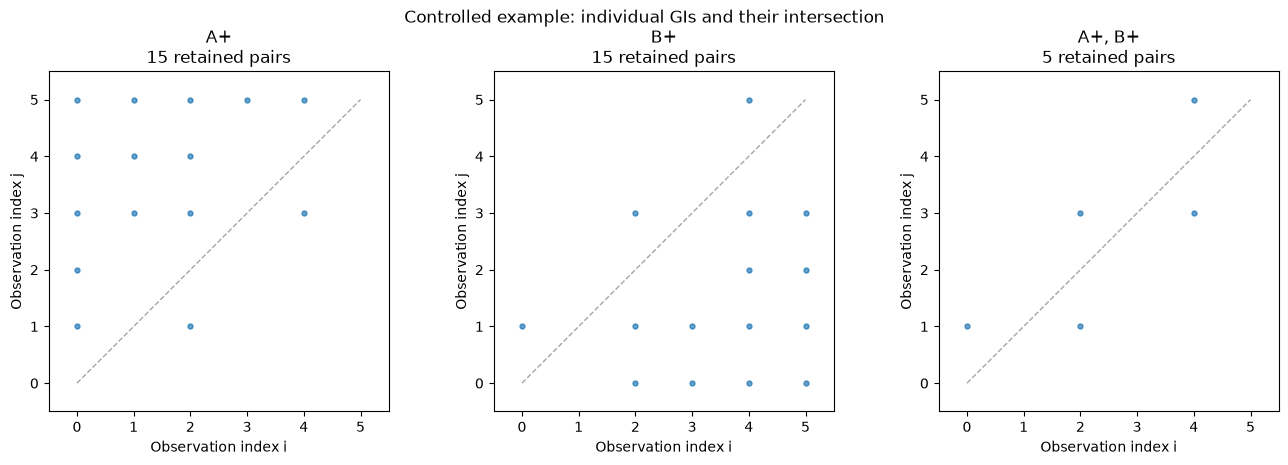

In [6]:
def plot_composition(engine, gi_keys, title):
    selections = [(key,) for key in gi_keys] + [tuple(gi_keys)]
    fig, axes = plt.subplots(1, len(selections), figsize=(4.5 * len(selections), 4.5))
    n = engine.row_count
    for ax, keys in zip(axes, selections):
        row, pairs = compose_pattern(engine, keys)
        ax.scatter(pairs[:, 0], pairs[:, 1], s=13, alpha=0.7)
        ax.plot([0, n - 1], [0, n - 1], "--", color="0.65", linewidth=1)
        ax.set(xlim=(-0.5, n - 0.5), ylim=(-0.5, n - 0.5),
               xlabel="Observation index i", ylabel="Observation index j",
               title=f"{row['Pattern']}\n{row['Pairs']} retained pairs")
        ax.set_aspect("equal")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


plot_composition(toy_engine, toy_keys, "Controlled example: individual GIs and their intersection")


**Read the plots as point sets.** Each dot is one retained comparison, and the dashed diagonal is an index reference. Joining all pairs in array order would introduce artificial line segments. For the toy GP, the points trace a narrow zigzag around the diagonal; the pair list shows which observations form the chain.

The toy result demonstrates why visual structure and the descriptor vector should be read together. It supports the low-dispersion part of the hypothesis, while the increase from zero GI singularity prevents a claim that all aspects improved.


## 6. Build GI and GP descriptor tables on the real data

Every GI and every discovered GP is now evaluated with the same helper. The GP's pairs are explicitly reconstructed as the intersection of its GIs. The assertions check that the reconstructed GP descriptors agree with those computed during mining, and that every joint pair belongs to each constituent.


In [7]:
gi_rows, gp_rows = [], []
comparisons, hypothesis_rows = [], []
for name, miner in miners.items():
    engine = miner.mining_engine
    constituents = {}
    for key in sorted(engine.valid_bins):
        row, pairs = compose_pattern(engine, (key,))
        constituents[key] = (row, pairs)
        gi_rows.append({"Dataset": name, **row})

    for pattern in engine.gradual_patterns or []:
        keys = tuple(sorted(pattern.to_string(), key=lambda key: GI.from_string(key).attribute_col))
        joint, pairs = compose_pattern(engine, keys)
        gp_rows.append({"Dataset": name, **joint})
        assert np.isclose(joint["Density"], pattern.density)
        assert np.isclose(joint["Singularity Score"], pattern.singularity_score)
        assert np.isclose(joint["Rank Dispersion"], pattern.rank_dispersion)
        joint_set = set(map(tuple, pairs))
        baseline_rows = []
        for key in keys:
            baseline, gi_pairs = constituents[key]
            baseline_rows.append(baseline)
            assert joint_set <= set(map(tuple, gi_pairs))
            comparisons.append({
                "Dataset": name, "GP": joint["Pattern"], "GI": baseline["Pattern"],
                "Pair retention": len(pairs) / len(gi_pairs),
                "GP coverage": joint["Active coverage"],
                "GP kappa": joint["Graph Connectivity"],
                "Delta kappa": joint["Graph Connectivity"] - baseline["Graph Connectivity"],
                "Delta Si": joint["Singularity Score"] - baseline["Singularity Score"],
                "Delta variance": joint["Rank variance"] - baseline["Rank variance"],
            })
        hypothesis_rows.append({
            "Dataset": name, "GP": joint["Pattern"],
            "Connected, full coverage": joint["Graph Connectivity"] == 1 and joint["Active coverage"] == 1,
            "Lower Si than every GI": all(joint["Singularity Score"] < row["Singularity Score"] for row in baseline_rows),
            "Lower variance than every GI": all(joint["Rank variance"] < row["Rank variance"] for row in baseline_rows),
        })

gi_df = pd.DataFrame(gi_rows)
gp_df = pd.DataFrame(gp_rows)
comparison_df = pd.DataFrame(comparisons)
hypothesis_df = pd.DataFrame(hypothesis_rows)
display(gi_df.round(3))
display(gp_df.round(3))


,Dataset,Pattern,Density,Avg. Deviation from Diagonal,Rank Dispersion,Rank variance,Graph Connectivity,Singularity Score,Pairs,Active coverage
0,Rainfall,NRB (mm)+,1.000,8.000,5.292,28.000,1,0.000,253,1.0
1,Rainfall,NRB (mm)-,1.000,8.000,5.292,28.000,1,0.000,253,1.0
2,Rainfall,KAK (mm)+,1.000,8.000,5.292,28.000,1,0.000,253,1.0
3,Rainfall,KAK (mm)-,1.000,8.000,5.292,28.000,1,0.000,253,1.0
4,Rainfall,MAK (mm)+,0.996,8.020,5.293,28.012,1,0.004,252,1.0
5,Rainfall,MAK (mm)-,0.996,8.020,5.293,28.012,1,0.004,252,1.0
6,Rainfall,WAJ (mm)+,0.992,8.020,5.308,28.171,1,0.007,251,1.0
7,Rainfall,WAJ (mm)-,0.992,8.020,5.308,28.171,1,0.007,251,1.0
8,EVI,NRB (EVI)+,1.000,8.000,5.292,28.000,1,0.000,253,1.0
9,EVI,NRB (EVI)-,1.000,8.000,5.292,28.000,1,0.000,253,1.0


,Dataset,Pattern,Density,Avg. Deviation from Diagonal,Rank Dispersion,Rank variance,Graph Connectivity,Singularity Score,Pairs,Active coverage
0,Rainfall,"NRB (mm)+, KAK (mm)+",0.688,8.011,5.381,28.954,1,0.525,174,1.000
1,Rainfall,"NRB (mm)+, MAK (mm)+",0.557,7.291,4.926,24.263,1,1.902,141,1.000
2,Rainfall,"NRB (mm)+, WAJ (mm)+",0.581,7.769,5.154,26.559,1,1.333,147,1.000
3,Rainfall,"KAK (mm)+, MAK (mm)+",0.506,8.281,5.404,29.202,1,1.206,128,1.000
4,Rainfall,"KAK (mm)+, WAJ (mm)+",0.506,7.992,5.332,28.430,1,1.518,128,0.957
5,Rainfall,"MAK (mm)+, WAJ (mm)+",0.585,8.095,5.515,30.410,1,1.556,148,1.000
6,EVI,"NRB (EVI)+, KAK (EVI)+",0.545,7.877,5.216,27.209,1,1.159,138,1.000
7,EVI,"NRB (EVI)+, MAK (EVI)+",0.534,8.156,5.446,29.657,1,1.357,135,1.000
8,EVI,"NRB (EVI)+, WAJ (EVI)-",0.526,7.774,5.322,28.325,1,1.172,133,1.000
9,EVI,"KAK (EVI)+, MAK (EVI)-",0.636,8.311,5.706,32.562,1,0.826,161,1.000


## 7. Test each composition against its own constituents

The matched table below reports **GP minus constituent GI**, rather than a comparison of rainfall averages with EVI averages:

- `Pair retention` is $|W_{GP}|/|W_{GI}|$.
- Negative `Delta Si` or `Delta variance` supports the corresponding improvement proposed by the hypothesis. Positive values show a tradeoff or deterioration on that dimension.
- `GP kappa = 1` shows connectedness of participating observations. Check `GP coverage` as well.
- `Delta kappa = 0` when both GI and GP already have one component means connectivity was preserved.

The second table uses the strict reading of “more coherent than the individual GIs”: a connected GP with full coverage, lower singularity than **every** constituent, and lower variance than **every** constituent. Equality at an already ideal value is preservation, not a strict improvement. These flags describe this sample; they are not significance tests or a universal path-likeness score.


In [8]:
display(comparison_df.round(3))
criteria = [
    "Connected, full coverage", "Lower Si than every GI", "Lower variance than every GI",
]
hypothesis_df["All three criteria"] = hypothesis_df[criteria].all(axis=1)
display(hypothesis_df)
display(hypothesis_df.groupby("Dataset")[criteria + ["All three criteria"]].sum())


,Dataset,GP,GI,Pair retention,GP coverage,GP kappa,Delta kappa,Delta Si,Delta variance
0,Rainfall,"NRB (mm)+, KAK (mm)+",NRB (mm)+,0.688,1.000,1,0,0.525,0.954
1,Rainfall,"NRB (mm)+, KAK (mm)+",KAK (mm)+,0.688,1.000,1,0,0.525,0.954
2,Rainfall,"NRB (mm)+, MAK (mm)+",NRB (mm)+,0.557,1.000,1,0,1.902,-3.737
3,Rainfall,"NRB (mm)+, MAK (mm)+",MAK (mm)+,0.560,1.000,1,0,1.898,-3.749
4,Rainfall,"NRB (mm)+, WAJ (mm)+",NRB (mm)+,0.581,1.000,1,0,1.333,-1.441
5,Rainfall,"NRB (mm)+, WAJ (mm)+",WAJ (mm)+,0.586,1.000,1,0,1.326,-1.612
6,Rainfall,"KAK (mm)+, MAK (mm)+",KAK (mm)+,0.506,1.000,1,0,1.206,1.202
7,Rainfall,"KAK (mm)+, MAK (mm)+",MAK (mm)+,0.508,1.000,1,0,1.202,1.191
8,Rainfall,"KAK (mm)+, WAJ (mm)+",KAK (mm)+,0.506,0.957,1,0,1.518,0.430
9,Rainfall,"KAK (mm)+, WAJ (mm)+",WAJ (mm)+,0.510,0.957,1,0,1.511,0.259


,Dataset,GP,"Connected, full coverage",Lower Si than every GI,Lower variance than every GI,All three criteria
0,Rainfall,"NRB (mm)+, KAK (mm)+",True,False,False,False
1,Rainfall,"NRB (mm)+, MAK (mm)+",True,False,True,False
2,Rainfall,"NRB (mm)+, WAJ (mm)+",True,False,True,False
3,Rainfall,"KAK (mm)+, MAK (mm)+",True,False,False,False
4,Rainfall,"KAK (mm)+, WAJ (mm)+",False,False,False,False
5,Rainfall,"MAK (mm)+, WAJ (mm)+",True,False,False,False
6,EVI,"NRB (EVI)+, KAK (EVI)+",True,False,True,False
7,EVI,"NRB (EVI)+, MAK (EVI)+",True,False,False,False
8,EVI,"NRB (EVI)+, WAJ (EVI)-",True,False,False,False
9,EVI,"KAK (EVI)+, MAK (EVI)-",True,False,False,False


,"Connected, full coverage",Lower Si than every GI,Lower variance than every GI,All three criteria
Dataset,,,,
EVI,6,0,3,0
Rainfall,5,0,2,0


## 8. Inspect selected joint effects visually

Use the same point-set plots for two concrete compositions: rainfall `NRB+` with `KAK+`, and EVI `KAK+` with `MAK-`. Both were discovered above. The comparison is within each row of panels: two individual GIs followed by their joint GP. A sparser joint set indicates additional gradual constraints, and does not by itself establish lower correlation or better path-like structure.


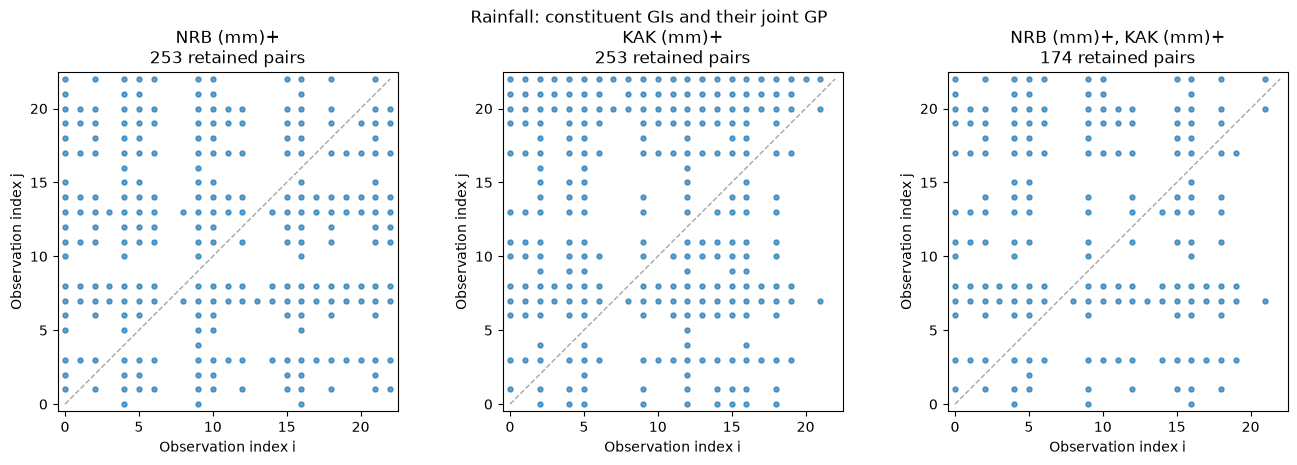

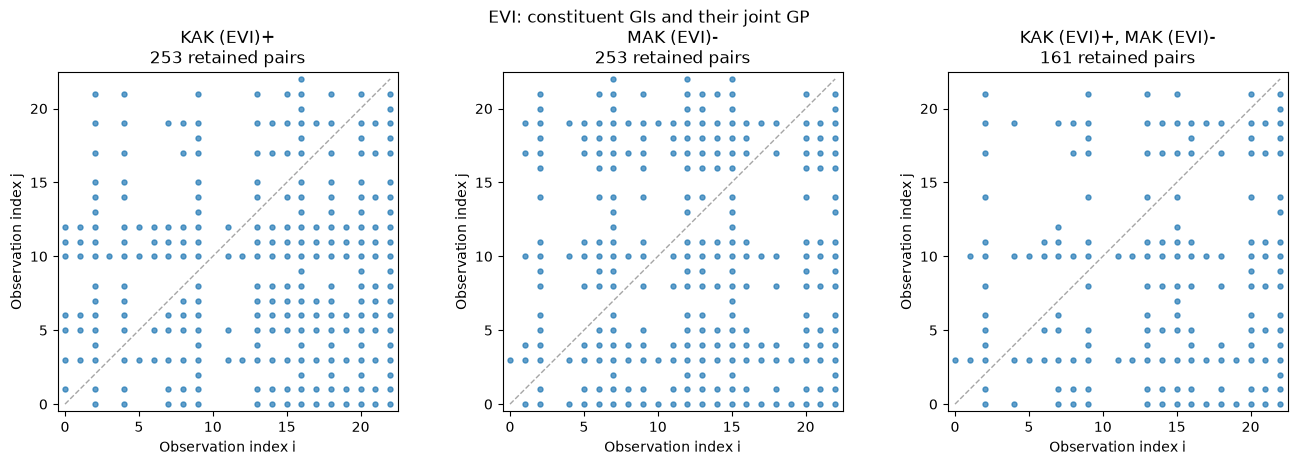

In [9]:
rain_engine = miners["Rainfall"].mining_engine
evi_engine = miners["EVI"].mining_engine
examples = {
    "Rainfall": (rain_engine, (
        item_key(rain_engine, "NRB (mm)", "+"), item_key(rain_engine, "KAK (mm)", "+"),
    )),
    "EVI": (evi_engine, (
        item_key(evi_engine, "KAK (EVI)", "+"), item_key(evi_engine, "MAK (EVI)", "-"),
    )),
}
for name, (engine, keys) in examples.items():
    plot_composition(engine, keys, f"{name}: constituent GIs and their joint GP")


The next plots keep the three hypothesis descriptors on separate axes. Compare the GI values with the GP value within each panel. This avoids mixing their numerical scales in a raw radar chart. Variance is in squared row-index units; singularity and component count have different meanings and scales.


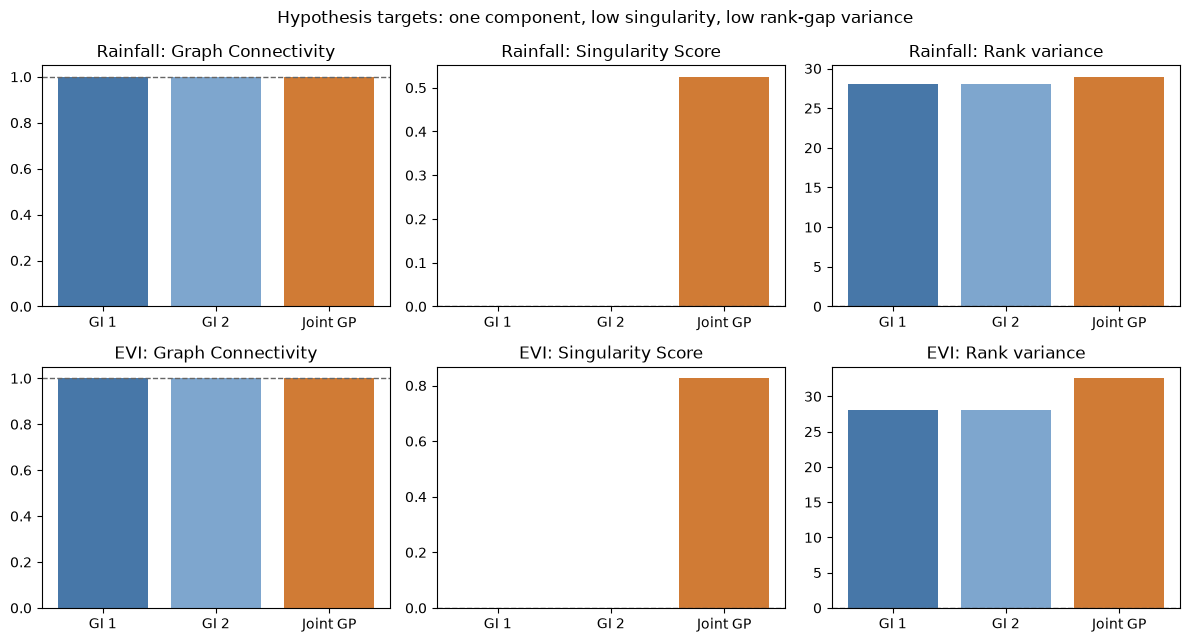

In [10]:
metrics = ["Graph Connectivity", "Singularity Score", "Rank variance"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), squeeze=False)
for row_index, (name, (engine, keys)) in enumerate(examples.items()):
    records = [compose_pattern(engine, (key,))[0] for key in keys]
    records.append(compose_pattern(engine, keys)[0])
    for ax, metric in zip(axes[row_index], metrics):
        ax.bar(["GI 1", "GI 2", "Joint GP"], [record[metric] for record in records],
               color=["#4777A8", "#7EA6CE", "#D07B35"])
        ax.set_title(f"{name}: {metric}")
        ax.set_ylim(bottom=0)
        ax.axhline(1 if metric == "Graph Connectivity" else 0, color="0.4", linestyle="--", linewidth=1)
fig.suptitle("Hypothesis targets: one component, low singularity, low rank-gap variance")
fig.tight_layout()
plt.show()


## 9. Extend the composition to a third attribute

Composing an existing GP with another GI uses the same intersection rule. Follow one rainfall composition from `NRB+` to `NRB+, KAK+` to `NRB+, KAK+, MAK+`. This manually selected three-item pattern is exploratory and may fall below the mining support threshold. Do not restrict structural inspection to only frequent candidates.


In [11]:
sequence = [item_key(rain_engine, name, "+") for name in ("NRB (mm)", "KAK (mm)", "MAK (mm)")]
progression_rows = [compose_pattern(rain_engine, sequence[:size])[0] for size in range(1, 4)]
progression_df = pd.DataFrame(progression_rows)
display(progression_df.round(3))
assert progression_df["Pairs"].is_monotonic_decreasing


,Pattern,Density,Avg. Deviation from Diagonal,Rank Dispersion,Rank variance,Graph Connectivity,Singularity Score,Pairs,Active coverage
0,NRB (mm)+,1.000,8.000,5.292,28.000,1,0.000,253,1.0
1,"NRB (mm)+, KAK (mm)+",0.688,8.011,5.381,28.954,1,0.525,174,1.0
2,"NRB (mm)+, KAK (mm)+, MAK (mm)+",0.375,7.674,5.218,27.230,1,1.708,95,1.0


## 10. Interpret the evidence

The proposed hypothesis is useful because it makes joint-effect analysis testable: inspect whether intersection retains $\kappa_g=1$ and moves $Si_g$ and $\sigma_g^2$ toward zero compared with the actual GIs. The outputs show which parts hold, rather than assuming composition always creates a better progression.

For the supplied datasets, all 12 discovered GPs retain one component among participating observations, and 11 retain full active coverage. Rainfall `KAK+, WAJ+` includes only 22 of 23 observations despite having one component. Singularity increases relative to the individual GIs, while rank-gap variance changes in both directions. The strict three-part improvement hypothesis is therefore **not supported in these examples**. This is still an informative joint effect: combined constraints select a more unevenly participating subset of comparisons, with a measurable change in the consistency of their index gaps.

The toy example explains why the qualification matters. A visually narrow, connected chain can have zero gap variance but positive singularity; a diffuse complete observation graph can have zero singularity. Descriptor values should be read as a profile, with point-set geometry and coverage, rather than as proof that the result is a DTW path.

**Use the analysis on your own data:** preserve a meaningful row order; select GIs by attribute and direction; reconstruct their intersection; inspect the paired descriptor changes and plots; then state which parts of the coherence hypothesis are supported. Empty intersections provide no joint gradual evidence. If literal DTW path validity is required, assess boundary, monotonicity and step constraints separately and compute an alignment with a suitable DTW method. These GRAANK comparisons do not estimate time lags, causal influence or statistical interaction effects.
